# W2 + Q2：亮区误检候选、真实阈值与 PL 计时

本轮使用真实 PYNQ-Z2、以太网和浏览器中的 Jupyter，无 HDMI。新 C2 使用双侧灰度支持和软惩罚；改善程度待真实板输出复核，并不保证所有亮区误检消失。原 A28 基线保留。

逐框 Shift+Enter，当前框结束且无报错再继续。红色报错或一分钟无新进展就停止并保留输出；不重复运行、不关闭失败内核、不重载 Overlay 或释放缓冲。原服务应先正常结束，不能与旧浏览器服务同时操作 FPGA。


## 1. 准备函数
左侧变成 In [数字] 且无红色报错即完成；没有打印正常。此步骤不加载 FPGA。


In [1]:
from w2_quality_board_test import prepare_w2, load_w2, smoke_w2, baseline_w2, candidate_w2, finish_w2


## 2. 核对文件
应出现 W2_PRECHECK_PASS，此步骤不加载 FPGA。Notebook 允许自动保存输出，但代码严格校验。


In [2]:
if 'w2_context' in globals():
    raise RuntimeError('Already prepared; do not rerun')
w2_retained = []
w2_context = prepare_w2('.', w2_retained)


W2_PRECHECK_PASS: paired files and official metadata; FPGA unchanged


## 3. 只加载一次
应出现 W2_LOAD_PASS；核对官方 DMA/GPIO 驱动、计数器身份与复位状态，尚未收发。


In [3]:
load_w2(w2_context)


W2_PROGRAMMING
W2_LOAD_PASS: single overlay, official drivers, observer identity/reset


## 4. 单帧验证
应出现 W2_SMOKE_PASS。一幅完整 256×256 图像逐字核对，并核对 PL 实际锁存参数和周期数。


In [4]:
smoke_w2(w2_context)


W2_SMOKE_RUNNING
W2_FRAME_PASS: 1/80 256 A T=28 stage=3 vessel_stripes
W2_SMOKE_PASS: one complete 256 frame and hardware cycle/parameter snapshot matched


## 5. 原算法回归
继续运行原 A4 的剩余 60 帧，连同上一步共 61 帧。最后 W2_BASELINE_PASS。


In [5]:
baseline_w2(w2_context)


W2_BASELINE_RUNNING
W2_FRAME_PASS: 2/80 256 A T=28 stage=0 gradient
W2_FRAME_PASS: 3/80 256 A T=28 stage=0 random
W2_FRAME_PASS: 4/80 256 A T=28 stage=1 gradient
W2_FRAME_PASS: 5/80 256 A T=28 stage=1 random
W2_FRAME_PASS: 6/80 256 A T=28 stage=2 gradient
W2_FRAME_PASS: 7/80 256 A T=28 stage=2 random
W2_FRAME_PASS: 8/80 256 A T=28 stage=3 gradient
W2_FRAME_PASS: 9/80 256 A T=28 stage=3 random
W2_FRAME_PASS: 10/80 512 A T=28 stage=0 gradient
W2_FRAME_PASS: 11/80 512 A T=28 stage=0 random
W2_FRAME_PASS: 12/80 512 A T=28 stage=1 gradient
W2_FRAME_PASS: 13/80 512 A T=28 stage=1 random
W2_FRAME_PASS: 14/80 512 A T=28 stage=2 gradient
W2_FRAME_PASS: 15/80 512 A T=28 stage=2 random
W2_FRAME_PASS: 16/80 512 A T=28 stage=3 gradient
W2_FRAME_PASS: 17/80 512 A T=28 stage=3 random
W2_FRAME_PASS: 18/80 256 A T=28 stage=1 impulse
W2_FRAME_PASS: 19/80 256 A T=28 stage=1 black
W2_FRAME_PASS: 20/80 256 A T=28 stage=1 white
W2_FRAME_PASS: 21/80 256 A T=28 stage=1 stare
W2_FRAME_PASS: 22/80 256 A T=28 st

## 6. C2 与真实改参
19 帧包含 A/C2 切换、T=1/27/28/29/255、256/512 和不同处理阶段。每帧重新送入 PL，并读取真实参数与计数。最后 W2_CANDIDATE_PASS。


In [6]:
candidate_w2(w2_context)


W2_CANDIDATE_RUNNING
W2_FRAME_PASS: 62/80 256 C2 T=28 stage=3 stare
W2_FRAME_PASS: 63/80 512 C2 T=28 stage=3 stare
W2_FRAME_PASS: 64/80 256 C2 T=27 stage=1 fov_edge
W2_FRAME_PASS: 65/80 512 C2 T=29 stage=2 fov_edge
W2_FRAME_PASS: 66/80 256 C2 T=1 stage=3 broken_line
W2_FRAME_PASS: 67/80 512 C2 T=255 stage=3 random
W2_FRAME_PASS: 68/80 256 C2 T=28 stage=0 vessel_stripes
W2_FRAME_PASS: 69/80 512 C2 T=28 stage=3 bright_cross
W2_FRAME_PASS: 70/80 256 C2 T=28 stage=3 checker
W2_FRAME_PASS: 71/80 256 C2 T=28 stage=3 impulse
W2_FRAME_PASS: 72/80 512 C2 T=28 stage=3 black
W2_FRAME_PASS: 73/80 512 A T=27 stage=3 stare
W2_FRAME_PASS: 74/80 512 C2 T=27 stage=3 stare
W2_FRAME_PASS: 75/80 512 A T=28 stage=3 stare
W2_FRAME_PASS: 76/80 512 C2 T=28 stage=3 stare
W2_FRAME_PASS: 77/80 512 A T=29 stage=3 stare
W2_FRAME_PASS: 78/80 512 C2 T=29 stage=3 stare
W2_FRAME_PASS: 79/80 256 A T=1 stage=3 stare
W2_FRAME_PASS: 80/80 256 A T=255 stage=3 stare
W2_CANDIDATE_PASS: C2/A switches, real thresholds and all 

## 7. 查看实际结果并打包
上排 A，下排 C2，均来自已完成且逐字核验的实际 DMA 输出。四列为原绿色、增强、掩膜、叠加；显示 W2_RESULTS_READY。只运行一次。


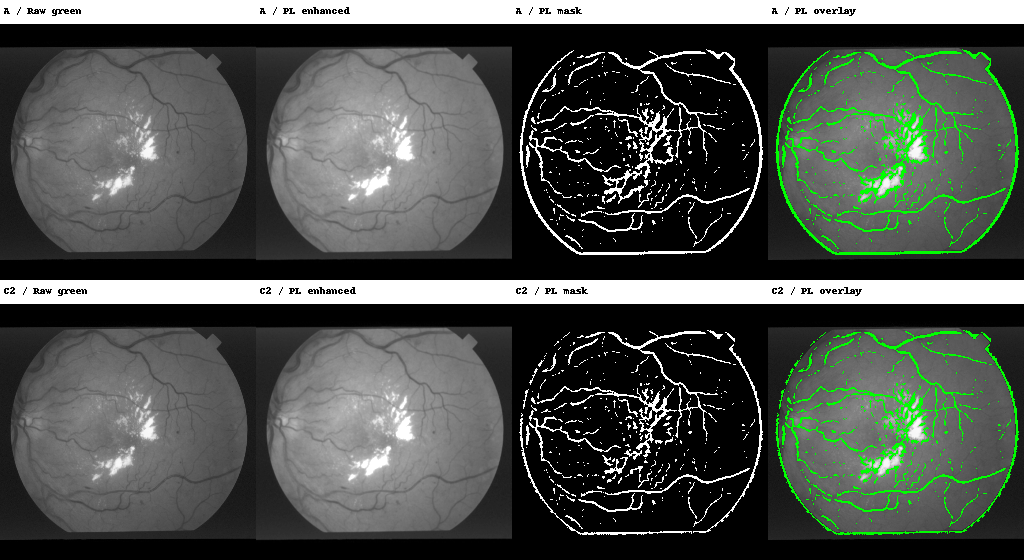

W2_RESULTS_READY: download w2_results_bundle.zip and the executed notebook


In [7]:
finish_w2(w2_context)


## 下载记录

Ctrl+S；File → Download as → Notebook，下载运行后的 `w2_quality_check.ipynb`。回文件列表下载 `w2_results_bundle.zip`，两份下载后反馈。可同时保存第7框的对比截图。

每帧保存原始输出、哈希、收发字节数、真实锁存参数、核心/背压周期和 PS 时间戳。预计算参考数组仅用于比较，不用于显示。核心时间包含流式等待，DMA 事务与 PL 重叠；不能相减得到纯 DMA。当前推理时间从配置开始到 DMA 完成后普通 CPU 快照结束，不含输入加载、分配、校验和导出。正式全数据精度、浏览器延迟/FPS、CPU 对照及稳定性仍是后续步骤。发布时板测状态 NOT_RUN，不能预填实测结果。
